# 05. 주요 업무지구 접근성과 가격의 관계

**질문:** 주요 업무지구 접근성은 가격과 어떤 관계가 있는가?

**방법과 지표**
- 단위: 법정동. 종속변수는 **동 보정 가격 수준**(2024-01~2026-09 일괄 제외 거래로 log(㎡당 가격) ~ 동 FE + 연월 FE + 면적·연식·층 구간을 추정한 동 FE, 서울 거래 가중 평균=0). 거래 30건 이상이고 통근시간이 있는 동만 쓴다.
- 설명변수(`dong_features.parquet`): 광화문·강남·여의도 대중교통 최단 통근시간(분), log 최근접 지하철역 거리, 반경 500m 버스정류소 수, log 단지 세대수 중앙값. 구 단위 종사자 수는 구 FE가 없는 사양에만 넣는다.
- **사양:** (A) 구 FE 없음, (B) 구 FE 포함(같은 구 안 동끼리 비교), (C) 통근시간 3곳을 함께 넣고 VIF로 공선성 확인. 표준오차는 HC1, 구 FE 없는 사양은 구 클러스터(25개)도 함께 본다.
- 잔차의 공간 자기상관: Moran's I(가까운 동 5개 가중치, 순열 999회).
- 서술용: 통근시간 구간별 동 가격 분포(박스플롯 분위수), 통근시간 지도(좌표 점).
- 예측 성능(공간 블록 교차검증 등)은 ml-engineer 범위다.

**사용한 교재 장:** 5장 다중회귀.
**교재에서 바꾼 점과 이유:** 거래를 독립 관측으로 두지 않고 동 단위로 모았다. 통근시간이 동마다 하나의 값이기 때문이다. 업무지구 3곳의 시간은 서로 상관이 커서 최단시간을 주변수로 쓰고 VIF를 보고한다. 동끼리 공간적으로 가까우면 잔차가 닮아 표준오차가 과소추정될 수 있어 Moran's I를 확인한다. 조율안의 kNN·k-means(생활권) 그림은 02b의 비가격 유형화로 대신했다.

**주의:** 같은 시점 동 간 비교다. "통근 10분 단축 시 가격 +x%" 같은 시나리오로 읽지 않는다. 통근시간은 2026-11-18 08:00 출발 구글 대중교통 경로(현재 교통망)이며, 이번 실행에서 API로 새로 수집하지 않았다. 통근시간이 없는 동 62개(종로·성북·중·용산 등 도심)는 분석에서 빠진다.

**코드 수준:** 계수(크기)만 필요한 단계는 pandas 평균 빼기와 `LinearRegression`으로 쓴 쉬운 함수(`ru.easy_index`, `ru.easy_dong_level` 등)를 쓴다. 원래 함수와 값이 같다(차이 1e-8 이하). 표준오차·검정·부트스트랩이 필요한 단계는 기존 재검증 코드를 그대로 쓴다. 이 노트북에서 쉬운 버전으로 바꾼 곳: 동 가격 수준, VIF. HC1·구 클러스터 표준오차, wild bootstrap, Moran's I는 원래 코드를 쓴다.


In [1]:
import os
import sys
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import reanalysis_utils as ru

SEED = ru.SEED
DATA = ROOT / "data"
plt = ru.set_korean_font()

In [2]:
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

OUT = ru.out_dir(ROOT, "05")
feat = pd.read_parquet(ROOT / "outputs" / "재검증" / "00_정제" / "dong_features.parquet")
tx = ru.load_tx(ROOT)
PER = ru.ym_range("2024-01", "2026-09")
d = tx[tx["in_base_nobulk"] & tx["contract_ym"].isin(PER)].reset_index(drop=True)
lev, lev_res = ru.easy_dong_level(d)
n0 = len(feat)
df = feat.merge(lev, on="dong_id", how="left", validate="one_to_one")
assert len(df) == n0
MIN_TX = 30
df["log_subway"] = np.log(df["subway_dist_m"])
df["log_hh"] = np.log(df["apt_households_median"])
df["log_gu_workers"] = np.log(df["gu_workers_2024"])
df["y"] = df["adj_log_level"] * 100
cond = pd.DataFrame({"tx_ge_30": df["n_tx"].fillna(0) >= MIN_TX, "commute_ok": ~df["commute_missing"],
                     "controls_ok": df[["log_subway", "bus_n_500m", "log_hh"]].notna().all(axis=1)})
s = df[cond.all(axis=1)].reset_index(drop=True)
pd.Series({"dongs_all": len(df), "tx_ge_30": int(cond["tx_ge_30"].sum()), "commute_ok": int(cond["commute_ok"].sum()),
           "analysis_dongs": len(s), "tx_used_level": int(lev_res["n"]),
           "excluded_tx_ge30_but_no_commute": int((cond["tx_ge_30"] & ~cond["commute_ok"]).sum())}).to_frame("n")

,n
dongs_all,338
tx_ge_30,259
commute_ok,276
analysis_dongs,255
tx_used_level,181874
excluded_tx_ge30_but_no_commute,4


`analysis_dongs`가 회귀에 쓴 동 수다. 거래가 30건 이상인데 통근시간이 없어 빠진 동 수(`excluded_tx_ge30_but_no_commute`)도 함께 적었다. 종속변수 `y`는 동 보정 가격 수준(서울 평균 대비 log×100)이다.

In [3]:
W = ru.knn_weights(s["lat"].to_numpy(), s["lon"].to_numpy(), k=5)
XA = ["commute_min", "log_subway", "bus_n_500m", "log_hh", "log_gu_workers"]
XB = ["commute_min", "log_subway", "bus_n_500m", "log_hh"]
XC = ["commute_gwanghwamun", "commute_gangnam", "commute_yeouido", "log_subway", "bus_n_500m", "log_hh"]


def fit(cols, gu_fe=False, label=""):
    X = s[cols].copy()
    if gu_fe:
        X = pd.concat([X, pd.get_dummies(s["gu"], prefix="gu", drop_first=True, dtype=float)], axis=1)
    X = sm.add_constant(X)
    m_hc = sm.OLS(s["y"], X).fit(cov_type="HC1")
    m_cl = sm.OLS(s["y"], X).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(s["gu"])[0]})
    I, p_I, EI = ru.morans_i(m_hc.resid.to_numpy(), W)
    ct = pd.DataFrame({"term": cols, "coef": m_hc.params[cols].values, "se_hc1": m_hc.bse[cols].values,
                       "p_hc1": m_hc.pvalues[cols].values, "se_gu_cluster": m_cl.bse[cols].values,
                       "p_gu_cluster": m_cl.pvalues[cols].values})
    ct["ci_low"] = ct["coef"] - 1.96 * ct["se_hc1"]
    ct["ci_high"] = ct["coef"] + 1.96 * ct["se_hc1"]
    ct["spec"], ct["n_dong"], ct["r2"], ct["adj_r2"] = label, int(m_hc.nobs), m_hc.rsquared, m_hc.rsquared_adj
    ct["moran_i"], ct["moran_p"] = I, p_I
    return ct, m_hc


cA, mA = fit(XA, False, "A 구 FE 없음")
cB, mB = fit(XB, True, "B 구 FE 포함")
cC, mC = fit(XC, False, "C 통근 3곳 동시")
coefs = pd.concat([cA, cB, cC], ignore_index=True)


def wild_p(cols, gu_fe, cluster_col):
    """동 단위 회귀의 commute_min 계수 wild bootstrap p값(구 FE 사양은 매 반복 구 FE로 다시 잔차화)."""
    X = s[cols].reset_index(drop=True)
    if gu_fe:
        r = ru.fe_ols(s["y"].to_numpy(), X, [s["gu"].to_numpy()], clusters=s[cluster_col].to_numpy(), dof_absorbed=True)
    else:
        r = ru.fe_ols(s["y"].to_numpy(), sm.add_constant(X), [], clusters=s[cluster_col].to_numpy())
    return ru.wild_cluster_boot_p(r, "commute_min", s[cluster_col].to_numpy(), B=999)[0]


wb = {("A 구 FE 없음", "dong_id"): wild_p(XA, False, "dong_id"), ("A 구 FE 없음", "gu"): wild_p(XA, False, "gu"),
      ("B 구 FE 포함", "dong_id"): wild_p(XB, True, "dong_id"), ("B 구 FE 포함", "gu"): wild_p(XB, True, "gu")}
coefs["wild_p_dong"] = [wb.get((sp_, "dong_id")) if t == "commute_min" else np.nan for sp_, t in zip(coefs["spec"], coefs["term"])]
coefs["wild_p_gu"] = [wb.get((sp_, "gu")) if t == "commute_min" else np.nan for sp_, t in zip(coefs["spec"], coefs["term"])]
coefs[["spec", "term", "coef", "se_hc1", "p_hc1", "p_gu_cluster", "wild_p_dong", "wild_p_gu", "ci_low", "ci_high", "n_dong", "r2", "moran_i", "moran_p"]].round(4)

,spec,term,coef,se_hc1,p_hc1,p_gu_cluster,wild_p_dong,wild_p_gu,ci_low,ci_high,n_dong,r2,moran_i,moran_p
0,A 구 FE 없음,commute_min,-1.1234,0.1718,0.0000,0.0019,0.001,0.004,-1.4601,-0.7867,255,0.4123,0.6056,0.001
1,A 구 FE 없음,log_subway,-0.0435,4.3648,0.9921,0.9924,NaN,NaN,-8.5984,8.5115,255,0.4123,0.6056,0.001
2,A 구 FE 없음,bus_n_500m,-0.4317,0.2346,0.0658,0.3121,NaN,NaN,-0.8916,0.0282,255,0.4123,0.6056,0.001
3,A 구 FE 없음,log_hh,23.6643,4.4514,0.0000,0.0000,NaN,NaN,14.9396,32.3890,255,0.4123,0.6056,0.001
4,A 구 FE 없음,log_gu_workers,20.9415,3.6230,0.0000,0.0431,NaN,NaN,13.8405,28.0425,255,0.4123,0.6056,0.001
5,B 구 FE 포함,commute_min,-1.0783,0.1880,0.0000,0.0000,0.001,0.001,-1.4468,-0.7098,255,0.7560,0.1669,0.001
6,B 구 FE 포함,log_subway,1.8329,3.5416,0.6048,0.6296,NaN,NaN,-5.1086,8.7744,255,0.7560,0.1669,0.001
7,B 구 FE 포함,bus_n_500m,-0.1185,0.1803,0.5112,0.6980,NaN,NaN,-0.4719,0.2349,255,0.7560,0.1669,0.001
8,B 구 FE 포함,log_hh,17.8867,3.1464,0.0000,0.0000,NaN,NaN,11.7197,24.0537,255,0.7560,0.1669,0.001
9,C 통근 3곳 동시,commute_gwanghwamun,-0.3058,0.1967,0.1200,0.3606,NaN,NaN,-0.6913,0.0797,255,0.5201,0.4974,0.001


계수는 동 보정 가격 수준(log×100, 대략 %)의 차이다. 예를 들어 `commute_min` 계수가 −1이면 최단 통근시간이 1분 긴 동이 약 1% 낮은 경향이다. 구 FE를 넣으면 같은 구 안의 동끼리만 비교한다(구 단위 종사자 수는 식별되지 않아 뺐다). `p_gu_cluster`는 구 25개 클러스터 표준오차의 p값이다. `wild_p_dong`/`wild_p_gu`는 최단 통근 계수의 wild bootstrap p값(동 단위 / 구 25개 클러스터 단위, 구 FE 사양은 매 반복 구 FE로 다시 잔차화)이다. 구 단위 wild bootstrap은 같은 구 안 동끼리의 잔차 상관을 허용하므로 공간 자기상관에 대한 보수적 점검이다. `moran_i`가 0보다 크고 `moran_p`가 작으면 잔차가 공간적으로 뭉쳐 있어 표준오차가 과소추정됐을 수 있다.

In [4]:
def vif_table(cols, label):
    """VIF = 1 / (1 − R²). R²는 한 변수를 나머지 변수로 LinearRegression 했을 때의 설명력."""
    rows = []
    for c in cols:
        others = [o for o in cols if o != c]
        r2 = LinearRegression().fit(s[others], s[c]).score(s[others], s[c])
        rows.append({"spec": label, "term": c, "vif": 1 / (1 - r2)})
    return pd.DataFrame(rows)


vif = pd.concat([vif_table(XA, "A 구 FE 없음"), vif_table(XC, "C 통근 3곳 동시")], ignore_index=True)
corr3 = s[["commute_gwanghwamun", "commute_gangnam", "commute_yeouido"]].corr()
display(vif.round(2))
corr3.round(3)

,spec,term,vif
0,A 구 FE 없음,commute_min,1.63
1,A 구 FE 없음,log_subway,1.26
2,A 구 FE 없음,bus_n_500m,1.19
3,A 구 FE 없음,log_hh,1.03
4,A 구 FE 없음,log_gu_workers,1.35
5,C 통근 3곳 동시,commute_gwanghwamun,2.16
6,C 통근 3곳 동시,commute_gangnam,1.17
7,C 통근 3곳 동시,commute_yeouido,1.82
8,C 통근 3곳 동시,log_subway,1.44
9,C 통근 3곳 동시,bus_n_500m,1.23


,commute_gwanghwamun,commute_gangnam,commute_yeouido
commute_gwanghwamun,1.000,0.133,0.635
commute_gangnam,0.133,1.000,0.293
commute_yeouido,0.635,0.293,1.000


VIF가 10을 넘으면 공선성이 커서 개별 계수를 해석하기 어렵다. 통근시간 3곳의 상관도 함께 보였다.

## 2. 통근시간 구간별 분포(서술용)

In [5]:
s["commute_bin"] = pd.cut(s["commute_min"], [0, 20, 30, 40, np.inf], labels=["≤20분", "20~30분", "30~40분", "40분 초과"]).astype(str)
box = (s.groupby("commute_bin")["y"].describe(percentiles=[.05, .25, .5, .75, .95])
       .reindex(["≤20분", "20~30분", "30~40분", "40분 초과"]).reset_index())
box.round(1)

,commute_bin,count,mean,std,min,5%,25%,50%,75%,95%,max
0,≤20분,74.0,20.5,30.0,-37.3,-28.0,1.9,20.1,38.7,69.2,100.2
1,20~30분,76.0,13.0,37.4,-96.6,-33.0,-14.6,9.6,39.0,78.3,134.8
2,30~40분,62.0,-8.9,34.9,-64.2,-51.3,-32.7,-14.2,10.5,71.7,96.3
3,40분 초과,43.0,-29.0,29.1,-75.5,-70.6,-46.6,-34.7,-13.5,22.7,26.0


위 표는 통근시간 구간별 동 가격 수준 분포다.

In [6]:
gu_chk = s.groupby("gu").agg(commute_mean=("commute_min", "mean"), log_gu_workers=("log_gu_workers", "first"))
emp_corr = gu_chk["commute_mean"].corr(gu_chk["log_gu_workers"], method="spearman")
dest = s["commute_min_dest"].value_counts().rename("dongs")
display(dest.to_frame().T)
pd.Series({"spearman_gu_commute_vs_workers": emp_corr, "gu": len(gu_chk)}).round(3)

commute_min_dest,광화문,여의도,강남
dongs,123,78,54


spearman_gu_commute_vs_workers    -0.491
gu                                25.000
dtype: float64

구별 평균 통근시간과 구 종사자 수(2024)의 순위상관이 음(−)이면, 통근시간이 짧은 구에 일자리가 많다는 뜻이라 업무지구 3곳 정의가 고용 분포와 어긋나지 않는지 대략 확인할 수 있다. 최단 통근 업무지구별 동 수도 함께 보였다.

## 3. 저장

In [7]:
mapdf = df[["dong", "gu", "dong_id", "lat", "lon", "commute_min", "commute_min_dest", "commute_missing", "adj_log_level", "n_tx"]].copy()
mapdf["in_regression"] = mapdf["dong_id"].isin(s["dong_id"])
ru.save_chart_csv(mapdf, OUT, "fig_commute_map.csv")
ru.save_chart_csv(box, OUT, "fig_commute_box.csv")
ru.save_chart_csv(coefs, OUT, "fig_coef_specs.csv")
ru.save_chart_csv(vif, OUT, "table_vif.csv")

rows = []


def add(key, label, value, unit, n, note, src, claim="통계적 연관", ps="2024-01", pe="2026-09"):
    rows.append({"key": key, "label": label, "value": float(value), "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": "없음",
                 "claim_level": claim, "source_file": src, "note": note})


for ct, k in [(coefs[coefs["spec"] == "A 구 FE 없음"], "nofe"), (coefs[coefs["spec"] == "B 구 FE 포함"], "gufe")]:
    r = ct.set_index("term").loc["commute_min"]
    add(f"commute_min_coef_{k}", f"최단 통근 1분당 동 가격 수준 차이({r['spec']})", r["coef"], "log×100(≈%)/분", r["n_dong"],
        f"HC1 95% CI {r['ci_low']:.2f}~{r['ci_high']:.2f}, p={r['p_hc1']:.3g}, 구 클러스터 p={r['p_gu_cluster']:.3g}, wild p(동/구)={r['wild_p_dong']:.3g}/{r['wild_p_gu']:.3g}, R² {r['r2']:.3f}, 잔차 Moran's I {r['moran_i']:.3f}(p={r['moran_p']:.3f})",
        "fig_coef_specs.csv")
    for t in ["log_subway", "bus_n_500m"]:
        r = ct.set_index("term").loc[t]
        add(f"{t}_coef_{k}", f"{t} 계수({r['spec']})", r["coef"], "log×100(≈%)/단위", r["n_dong"],
            f"HC1 p={r['p_hc1']:.3g}, 구 클러스터 p={r['p_gu_cluster']:.3g}", "fig_coef_specs.csv")
    add(f"moran_i_{k}", f"잔차 Moran's I({ct['spec'].iloc[0]})", ct["moran_i"].iloc[0], "I", ct["n_dong"].iloc[0],
        f"가까운 동 5개 가중치, 순열 p={ct['moran_p'].iloc[0]:.3f}", "fig_coef_specs.csv")
add("vif_max_three_commute", "통근 3곳 동시 투입 시 최대 VIF", vif[vif["spec"] == "C 통근 3곳 동시"]["vif"].max(), "VIF", len(s),
    "통근시간 3곳의 공선성", "table_vif.csv")
add("n_dongs_regression", "회귀 표본 동 수", len(s), "개", len(s), f"거래 {MIN_TX}건 이상 & 통근시간 있음. 통근 결측 동은 API 미수집으로 제외", "fig_commute_map.csv", "단순 변화")
for _, r in box.iterrows():
    add(f"commute_bin_median_{['≤20분', '20~30분', '30~40분', '40분 초과'].index(r['commute_bin'])}", f"통근 {r['commute_bin']} 동 가격 수준 중앙값",
        r["50%"], "log×100(≈%)", int(r["count"]), "서울 거래 가중 평균=0", "fig_commute_box.csv", "단순 변화")
summary = ru.save_summary(rows, OUT)
ru.save_meta({
    "question": "주요 업무지구 접근성은 가격과 어떤 관계가 있는가?",
    "method": "동 보정 가격 수준(2024-01~2026-09) ~ 최단 통근시간 + 역거리 + 버스정류소 + 세대수(+구 종사자), 구 FE 포함/제외, 통근 3곳 VIF, 잔차 Moran's I(kNN 5), 통근 구간 박스플롯",
    "textbook_chapters": ["5장 다중회귀"],
    "sample_period": "가격 2024-01~2026-09, 통근시간 2026-11-18 08:00 출발(현재 시점)",
    "sample_size": {"dongs": len(s), "tx_for_level": int(lev_res["n"])},
    "data_files": ["outputs/재검증/00_정제/dong_features.parquet", "outputs/재검증/00_정제/transactions.parquet"],
    "limitations": ["같은 시점 동 간 비교이며 통근시간 변화의 가격 반응이 아니다", "통근시간은 현재 교통망·단일 출발시각 기준",
                    "API 미수집: 통근시간 결측 동 62개(도심 집중)는 분석에서 빠짐", "강남 업무지구가 한 지점이라 삼성·대치 등은 왜곡 가능",
                    "구 종사자 수는 구 단위라 구 FE 사양에서 식별 불가", "잔차 공간 자기상관이 남으면 표준오차가 과소추정됨"],
}, OUT)
summary[["key", "value", "note"]]

,key,value,note
0,commute_min_coef_nofe,-1.123374,"HC1 95% CI -1.46~-0.79, p=6.2e-11, 구 클러스터 p=0...."
1,log_subway_coef_nofe,-0.043487,"HC1 p=0.992, 구 클러스터 p=0.992"
2,bus_n_500m_coef_nofe,-0.431709,"HC1 p=0.0658, 구 클러스터 p=0.312"
3,moran_i_nofe,0.605643,"가까운 동 5개 가중치, 순열 p=0.001"
4,commute_min_coef_gufe,-1.078277,"HC1 95% CI -1.45~-0.71, p=9.74e-09, 구 클러스터 p=1..."
5,log_subway_coef_gufe,1.832909,"HC1 p=0.605, 구 클러스터 p=0.63"
6,bus_n_500m_coef_gufe,-0.118464,"HC1 p=0.511, 구 클러스터 p=0.698"
7,moran_i_gufe,0.166861,"가까운 동 5개 가중치, 순열 p=0.001"
8,vif_max_three_commute,2.157391,통근시간 3곳의 공선성
9,n_dongs_regression,255.000000,거래 30건 이상 & 통근시간 있음. 통근 결측 동은 API 미수집으로 제외


## 결론
수치는 거래 30건 이상이고 통근시간이 있는 255개 동, 2024-01~2026-09 동 보정 가격 수준(서울 평균 대비 log×100)에 대한 같은 시점 동 간 통계적 연관이다(`fig_coef_specs.csv`).
- **최단 통근시간:** 업무지구(광화문·강남·여의도) 최단 대중교통 통근시간이 1분 긴 동은 가격 수준이 약 1.1% 낮은 경향이었다(구 FE 없음 −1.12, HC1 95% CI −1.46~−0.79; 구 FE 포함 −1.08, CI −1.45~−0.71). **같은 구 안 동끼리 비교해도 기울기가 거의 같았다.** wild bootstrap p값은 동 단위 0.001(두 사양), 구 25개 클러스터 단위 0.004(구 FE 없음)·0.001(구 FE 포함)로, 같은 구 안 동끼리의 잔차 상관을 허용해도 연관이 유지됐다.
- **구간별(단순 변화):** 동 가격 수준 중앙값은 통근 20분 이하 +20.1, 20~30분 +9.6, 30~40분 −14.2, 40분 초과 −34.7(log×100)로 단조롭게 낮아졌다(`fig_commute_box.csv`).
- **업무지구별:** 3곳을 함께 넣으면 강남 통근시간 계수(−1.59/분, p<0.001)가 가장 크고, 여의도(−0.54)가 그다음이며, 광화문(−0.31)은 유의하지 않았다. VIF는 최대 2.2로 공선성은 크지 않다(`table_vif.csv`).
- **다른 접근성 변수:** 역거리·버스정류소 수는 구 FE 사양에서 유의하지 않았다. 단지 세대수 중앙값은 두 사양 모두 양(+)의 연관이 있었다(log 세대수 1 증가당 +17.9~+23.7).
- **공간 자기상관:** 잔차 Moran's I는 구 FE 없음 0.61, 구 FE 포함 0.17로 둘 다 순열 p=0.001이었다. 가까운 동끼리 잔차가 닮아 있어 **위 표준오차는 과소추정됐을 수 있다.** 구 FE를 넣으면 많이 줄지만 남는다.
- 구별 평균 통근시간과 구 종사자 수(2024)의 순위상관은 −0.49로, 통근시간이 짧은 구에 일자리가 많았다(업무지구 정의의 대략적 확인).

## 한계
- 같은 시점 동 간 비교다. 특정 동의 통근시간이 줄 때 가격이 얼마나 바뀌는지를 보여 주지 않는다.
- 통근시간은 2026-11-18 08:00 출발 한 번의 구글 대중교통 경로(현재 교통망)다. 이번 실행에서는 API로 새로 수집하지 않았고, 통근시간이 없는 62개 동(종로 20, 성북 12, 중구 10, 용산 7 등)은 빠졌다. 도심 동이 빠져 결과가 외곽·부도심 동 위주다.
- 강남 업무지구를 한 지점으로 잡아 삼성·대치 등 같은 업무권역 안의 동도 통근시간이 길게 잡힐 수 있다.
- 잔차의 공간 자기상관이 남아 있어 HC1 p값은 실제보다 작게 나왔을 수 있다. 구 단위 wild bootstrap으로 일부 보완했지만 구 경계를 넘는 상관은 반영하지 못한다.
- 구 종사자 수는 구 단위라 구 FE 사양에서는 식별되지 않는다.
- 단지 세대수와 가격의 연관은 대단지 신축·재건축 단지의 특성이 섞인 값이다.

## 시각화 (발표용): 기존 05의 그림 구성을 새 결과로 다시 그리기

기존 05의 그림 네 가지를 같은 순서로 만들었다.
1. 동별 통근시간 지도
2. 통근 구간별 가격과 동별 산점도
3. 변수 중요도
4. 업무지구별 부분의존 그래프

새 05에는 Random Forest가 없어서 ③은 회귀 계수(1분당 차이, 95% 신뢰구간)로, ④는 업무지구별 산점도와 단순 추세선으로 바꿨다. 가격은 면적·연식·층을 맞춘 동 가격 수준(2024-01~2026-09)이다.

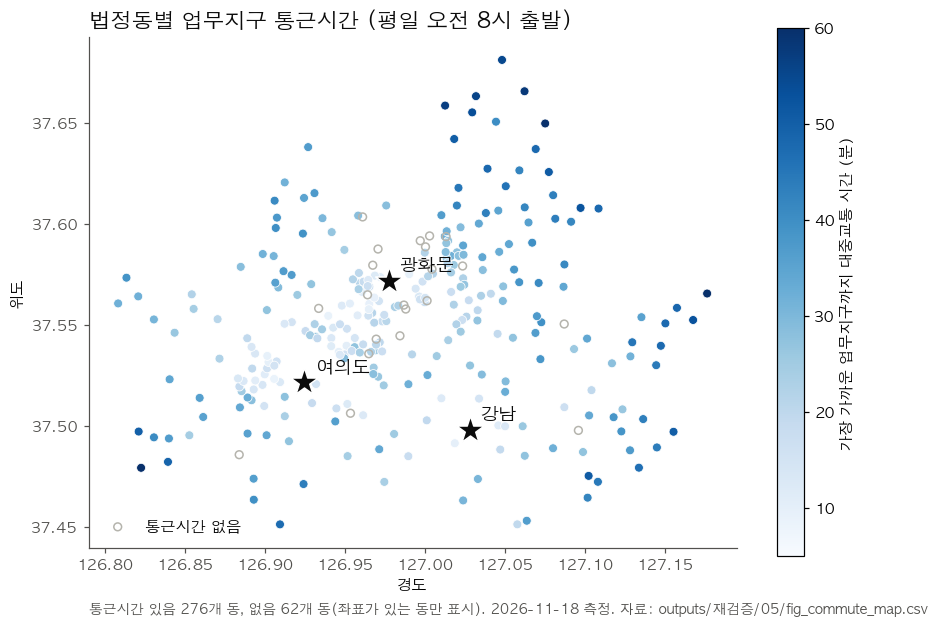

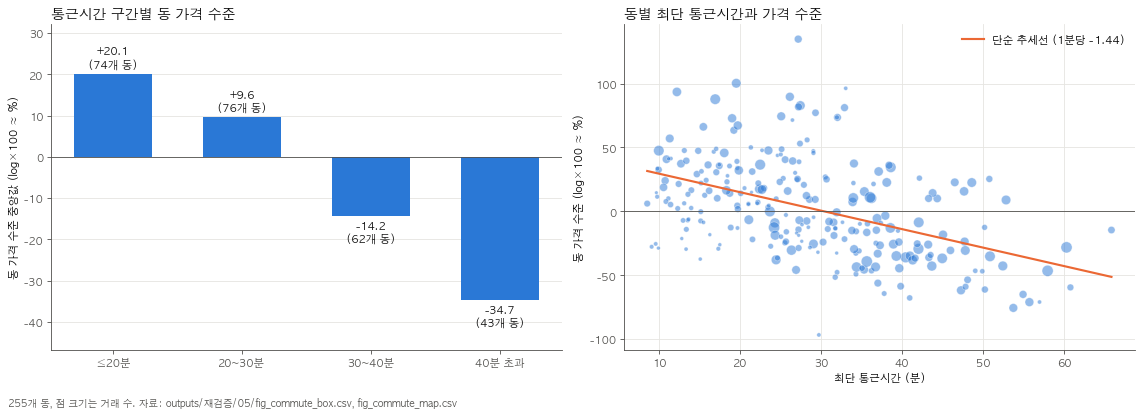

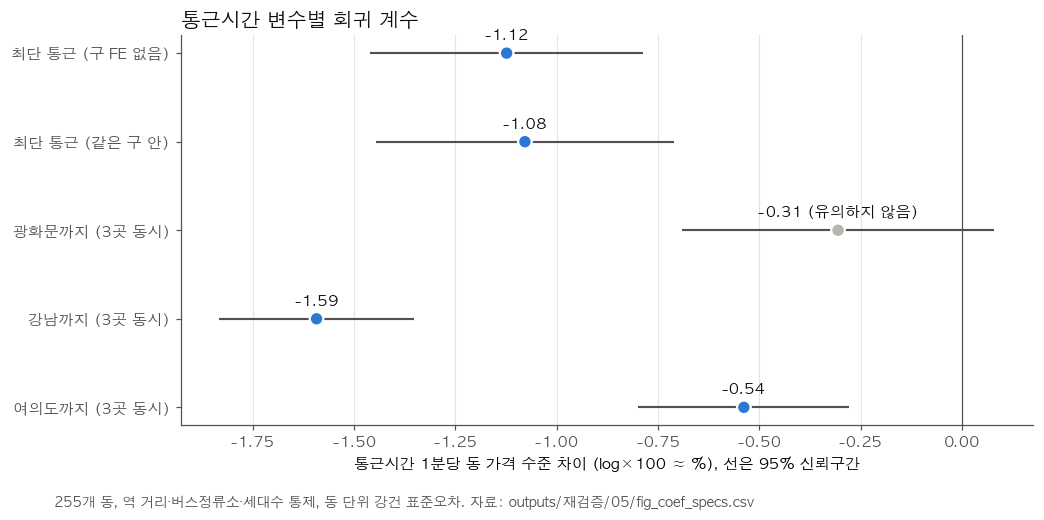

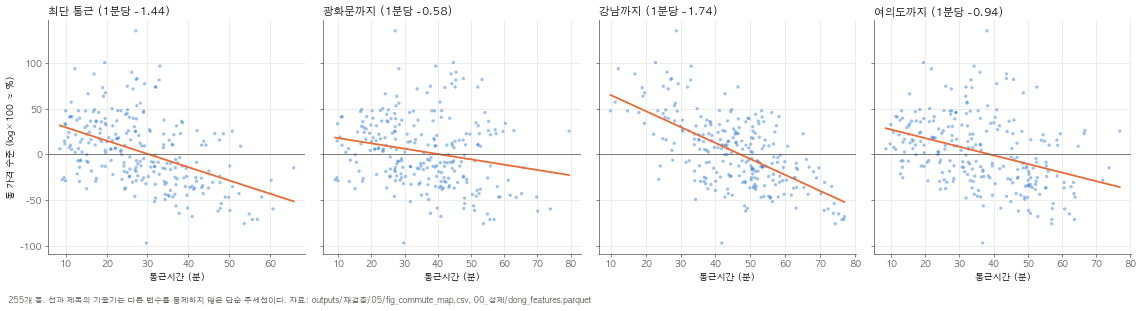

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "05"
m = pd.read_csv(OUT / "fig_commute_map.csv")
feat = pd.read_parquet(ROOT / "outputs" / "재검증" / "00_정제" / "dong_features.parquet",
                       columns=["dong_id", "commute_gwanghwamun", "commute_gangnam", "commute_yeouido"])
m = m.merge(feat, on="dong_id", how="left")
reg = m[m["in_regression"]].copy()
reg["y"] = reg["adj_log_level"] * 100
HUBS = pd.DataFrame({"name": ["광화문", "강남", "여의도"], "lon": [126.977170, 127.027912, 126.924357],
                     "lat": [37.571525, 37.497990, 37.521747]})   # data/05_직주근접/지하철역 좌표정보.csv

# ① 지도
fig, ax = plt.subplots(figsize=(9.5, 7.8))
ok = m[~m["commute_missing"] & m["lat"].notna()]
miss = m[m["commute_missing"] & m["lat"].notna()]
sc = ax.scatter(ok["lon"], ok["lat"], c=ok["commute_min"], cmap="Blues", vmin=5, vmax=60, s=34, edgecolor="white", lw=0.5)
ax.scatter(miss["lon"], miss["lat"], s=26, facecolor="none", edgecolor="#b5b4ad", lw=1, label="통근시간 없음")
ax.scatter(HUBS["lon"], HUBS["lat"], marker="*", s=360, color=INK, edgecolor="white", zorder=3)
for _, r in HUBS.iterrows():
    ax.annotate(r["name"], (r["lon"], r["lat"]), xytext=(7, 7), textcoords="offset points", fontsize=12, weight="bold", color=INK)
fig.colorbar(sc, ax=ax, shrink=0.8, label="가장 가까운 업무지구까지 대중교통 시간 (분)")
ax.set_aspect(1 / np.cos(np.radians(37.55)))
ax.set(xlabel="경도", ylabel="위도")
ax.set_title("법정동별 업무지구 통근시간 (평일 오전 8시 출발)", loc="left", fontsize=14, color=INK)
ax.legend(loc="lower left", frameon=False)
style(ax, grid=None)
ax.text(0, -0.13, f"통근시간 있음 {len(ok)}개 동, 없음 {int(m['commute_missing'].sum())}개 동(좌표가 있는 동만 표시). "
         "2026-11-18 측정. 자료: outputs/재검증/05/fig_commute_map.csv", transform=ax.transAxes, fontsize=9, color=INK2)
save(fig, "viz_05_1_map.png")

# ② 통근 구간별 가격 + 동별 산점도
box = pd.read_csv(OUT / "fig_commute_box.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.2))
a1.bar(box["commute_bin"], box["50%"], color=SERIES[0], width=0.6)
for i, (v, n) in enumerate(zip(box["50%"], box["count"])):
    a1.annotate(f"{v:+.1f}\n({int(n)}개 동)", (i, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                ha="center", va="bottom" if v >= 0 else "top", fontsize=10, color=INK)
a1.set_ylim(box["50%"].min() - 12, box["50%"].max() + 12)
a1.axhline(0, color=INK2, lw=0.8)
a1.set_ylabel("동 가격 수준 중앙값 (log×100 ≈ %)")
a1.set_title("통근시간 구간별 동 가격 수준", loc="left", fontsize=13, color=INK)
style(a1)
a2.scatter(reg["commute_min"], reg["y"], s=np.clip(np.sqrt(reg["n_tx"]) * 2, 10, 110), color=SERIES[0], alpha=0.5, edgecolor="white", lw=0.6)
z = np.polyfit(reg["commute_min"], reg["y"], 1)
xs = np.linspace(reg["commute_min"].min(), reg["commute_min"].max(), 50)
a2.plot(xs, np.polyval(z, xs), color=SERIES[1], lw=2, label=f"단순 추세선 (1분당 {z[0]:+.2f})")
a2.axhline(0, color=INK2, lw=0.8)
a2.set(xlabel="최단 통근시간 (분)", ylabel="동 가격 수준 (log×100 ≈ %)")
a2.set_title("동별 최단 통근시간과 가격 수준", loc="left", fontsize=13, color=INK)
a2.legend(loc="upper right", frameon=False)
style(a2, grid="both")
fig.text(0.01, -0.03, f"{len(reg)}개 동, 점 크기는 거래 수. 자료: outputs/재검증/05/fig_commute_box.csv, fig_commute_map.csv",
         fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_05_2_bins_scatter.png")

# ③ 회귀 계수(기존 RF 변수 중요도 자리)
cs = pd.read_csv(OUT / "fig_coef_specs.csv")
rows = [("최단 통근 (구 FE 없음)", "commute_min", "A 구 FE 없음"), ("최단 통근 (같은 구 안)", "commute_min", "B 구 FE 포함"),
        ("광화문까지 (3곳 동시)", "commute_gwanghwamun", "C 통근 3곳 동시"), ("강남까지 (3곳 동시)", "commute_gangnam", "C 통근 3곳 동시"),
        ("여의도까지 (3곳 동시)", "commute_yeouido", "C 통근 3곳 동시")]
k = pd.DataFrame([dict(label=l, **cs[(cs["term"] == t) & (cs["spec"] == sp)].iloc[0][["coef", "ci_low", "ci_high"]]) for l, t, sp in rows])
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(k))[::-1]
sig = (k["ci_high"] < 0) | (k["ci_low"] > 0)
ax.hlines(y, k["ci_low"], k["ci_high"], color=INK2, lw=1.4)
ax.scatter(k["coef"], y, s=80, color=[SERIES[0] if s_ else "#b5b4ad" for s_ in sig], zorder=3, edgecolor="white", lw=1.5)
for yi, v, s_ in zip(y, k["coef"], sig):
    ax.annotate(f"{v:+.2f}" + ("" if s_ else " (유의하지 않음)"), (v, yi), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=10, color=INK)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y, k["label"])
ax.set_xlabel("통근시간 1분당 동 가격 수준 차이 (log×100 ≈ %), 선은 95% 신뢰구간")
ax.set_title("통근시간 변수별 회귀 계수", loc="left", fontsize=13, color=INK)
style(ax, grid="x")
fig.text(0.01, -0.05, f"{int(cs['n_dong'].iloc[0])}개 동, 역 거리·버스정류소·세대수 통제, 동 단위 강건 표준오차. "
         "자료: outputs/재검증/05/fig_coef_specs.csv", fontsize=9, color=INK2)
save(fig, "viz_05_3_coefficients.png")

# ④ 업무지구별 산점도(기존 부분의존 그래프 자리)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharey=True)
for ax, (col, lab) in zip(axes, [("commute_min", "최단 통근"), ("commute_gwanghwamun", "광화문까지"),
                                 ("commute_gangnam", "강남까지"), ("commute_yeouido", "여의도까지")]):
    g = reg.dropna(subset=[col])
    ax.scatter(g[col], g["y"], s=14, color=SERIES[0], alpha=0.45, edgecolor="none")
    z = np.polyfit(g[col], g["y"], 1)
    xs = np.linspace(g[col].min(), g[col].max(), 30)
    ax.plot(xs, np.polyval(z, xs), color=SERIES[1], lw=2)
    ax.set_title(f"{lab} (1분당 {z[0]:+.2f})", loc="left", fontsize=12, color=INK)
    ax.set_xlabel("통근시간 (분)")
    ax.axhline(0, color=INK2, lw=0.8)
    style(ax, grid="both")
axes[0].set_ylabel("동 가격 수준 (log×100 ≈ %)")
fig.text(0.01, -0.04, f"{len(reg)}개 동. 선과 제목의 기울기는 다른 변수를 통제하지 않은 단순 추세선이다. "
         "자료: outputs/재검증/05/fig_commute_map.csv, 00_정제/dong_features.parquet", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_05_4_by_hub.png")
